# Complementaria Semana 15: Corrida larga, período de calentamiento y *batch means*

La semana pasada vimos que, cuando interesa el comportamiento **de largo plazo** de un sistema, las réplicas que arrancan vacías y duran poco están **sesgadas**: con réplicas de 20 minutos, la espera estimada era menos de la mitad de la real, y con un intervalo angosto y equivocado.

Hoy resolvemos ese problema con dos herramientas:

1. Identificar y descartar el **período de calentamiento** (*warm-up*).
2. Hacer **una sola corrida larga** y dividirla en lotes (*batch means*) en lugar de muchas réplicas.

### Objetivo de hoy

Al final de la sesión deberías poder elegir un período de calentamiento a partir de una gráfica, construir un intervalo de confianza con *batch means* y decidir cuándo conviene esto y cuándo réplicas independientes.

| Bloque | Tema |
|---|---|
| 1 | El sistema y el problema del arranque |
| 2 | Elegir el período de calentamiento (método de Welch) |
| 3 | Una corrida larga y *batch means* |
| 4 | ¿Réplicas o *batch means*? |
| 5 | Ejercicio aplicado: ¿cuántos lotes? |

### Convenciones utilizadas

- $N(t)$: número de clientes en el sistema en el instante $t$; $L$ es su promedio de largo plazo.
- $T$: duración de una corrida; $T_w$: período de calentamiento (*warm-up*) que se descarta.
- $B$: número de lotes; cada lote dura $(T - T_w)/B$.
- $\bar N_b$: promedio temporal de $N(t)$ dentro del lote $b$.
- $r_1$: autocorrelación de orden 1 (lag-1) entre lotes consecutivos.
- $R$, HW, $\lambda$, $\mu$, $s$, $\rho$: como en la semana 14.

## 0. Preparación

Este notebook se trabaja en **VS Code**, sobre el ambiente virtual de los tutoriales de la semana 1. Si te falta alguna librería, descomenta la primera línea.

In [1]:
# %pip install numpy pandas matplotlib scipy simpy

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import simpy
from scipy import stats

Las herramientas de hoy son las de siempre, con una novedad: el simulador guarda la **trayectoria** completa de $N(t)$, es decir, cada instante en que alguien entra o sale y cuántos quedan. Con esa escalera calculamos promedios temporales **exactos** (suma de rectángulos, como en la semana 5) sobre cualquier intervalo de tiempo. Como en las semanas 13 y 14, en el simulador `# NUEVO:` marca lo que no estaba en la semana 5 y `# CAMBIO:` lo que se modificó.

In [2]:
def simular_trayectoria(lam, mu, s, T, semilla=0):
    # Cola M/M/s de la semana 5 que guarda la trayectoria completa de N(t).
    # CAMBIO: en lugar del monitor de la semana 5 (áreas y listas de esperas) solo guardamos
    # la "escalera" N(t). Con ella calculamos después el promedio de cualquier tramo de tiempo
    # (función promedio_temporal), que es lo que necesitan el warm-up y los lotes.
    #   ts[i] = instante del i-ésimo cambio,  ns[i] = clientes en el sistema desde ese instante
    rng = np.random.default_rng(semilla)
    ts, ns = [0.0], [0]          # NUEVO: la escalera arranca en t = 0 con el sistema vacío
    m = {"n": 0}                 # clientes en el sistema en este momento

    def registrar(env, cambio):
        # NUEVO: suma +1 (llegada) o -1 (salida) y anota el nuevo escalón (instante, N)
        m["n"] += cambio
        ts.append(env.now)
        ns.append(m["n"])

    def cliente(env, servidores):
        registrar(env, +1)                         # llega
        with servidores.request() as turno:
            yield turno
            yield env.timeout(rng.exponential(1 / mu))
        registrar(env, -1)                         # sale

    def generador(env, servidores):
        while True:
            yield env.timeout(rng.exponential(1 / lam))
            env.process(cliente(env, servidores))

    env = simpy.Environment()
    servidores = simpy.Resource(env, capacity=s)
    env.process(generador(env, servidores))
    env.run(until=T)
    return np.array(ts), np.array(ns)


def N_en(ts, ns, instantes):
    # Valor de la escalera N(t) en los instantes pedidos (el último cambio en o antes de cada instante)
    return ns[np.searchsorted(ts, instantes, side="right") - 1]


def promedio_temporal(ts, ns, a, b):
    # (1/(b-a)) * integral de N(t) entre a y b, exacta: suma de rectángulos (semana 5)
    area = np.concatenate([[0.0], np.cumsum(ns[:-1] * np.diff(ts))])   # área acumulada en cada cambio
    def area_hasta(t):
        k = np.searchsorted(ts, t, side="right") - 1
        return area[k] + ns[k] * (t - ts[k])
    return (area_hasta(b) - area_hasta(a)) / (b - a)


def ic_t(datos, confianza=0.95):
    # Intervalo t de las semanas 3 y 14: devuelve (media, semiancho HW)
    datos = np.asarray(datos, dtype=float)
    R = len(datos)
    hw = stats.t.ppf((1 + confianza) / 2, R - 1) * datos.std(ddof=1) / np.sqrt(R)
    return datos.mean(), hw


def L_teorico(lam, mu, s):
    # L de la M/M/s por Erlang C (semana 13)
    a = lam / mu
    rho = a / s
    suma = sum(a**n / math.factorial(n) for n in range(s))
    termino_cola = a**s / (math.factorial(s) * (1 - rho))
    C = termino_cola / (suma + termino_cola)
    return C * rho / (1 - rho) + a

## 1. El sistema y el problema del arranque

Una **central de despacho de emergencias** opera 24/7 con $s = 3$ operadores. Las llamadas llegan con $\lambda = 2.7$ por minuto y cada una se atiende en un tiempo exponencial de media 1 minuto ($\mu = 1$). La utilización es $\rho = 0.9$: un sistema cargado. Como nunca cierra, interesa su comportamiento **de largo plazo**: el número promedio de llamadas en el sistema, $L$.

Para este sistema conocemos el valor exacto (Erlang C), y eso nos permite comprobar si los métodos de hoy funcionan.

In [3]:
lam, mu, s = 2.7, 1.0, 3
L_exacto = L_teorico(lam, mu, s)
print(f"ρ = {lam / (s * mu):.2f}     L exacto = {L_exacto:.3f} llamadas en el sistema")

ρ = 0.90     L exacto = 10.054 llamadas en el sistema


Cada corrida arranca con la central **vacía**, algo que en el sistema real nunca pasa: a cualquier hora del día ya hay llamadas en curso. Los primeros minutos de cada corrida no representan el largo plazo y, si los incluimos, el promedio sale sesgado hacia abajo.

## 2. Elegir el período de calentamiento: método de Welch

Una sola trayectoria de $N(t)$ es demasiado ruidosa para ver dónde termina el arranque. El **método de Welch** la limpia en dos pasos:

1. **Promediar entre réplicas:** correr $R$ réplicas cortas y, en cada instante $t$ de una grilla, promediar $N(t)$ entre ellas. Eso estima $E[N(t)]$, cómo evoluciona **en promedio** el sistema desde que arranca.
2. **Suavizar en el tiempo:** aplicar una media móvil a esa curva.

El período de calentamiento $T_w$ se elige donde la curva suavizada **deja de subir** y se queda oscilando alrededor de un valor estable. Es una decisión visual; conviene ser **conservador** (descartar un poco de más cuesta poco tiempo simulado; descartar de menos deja sesgo) y **reportar** el valor elegido.

> La grilla se evalúa con `N_en`, que lee el valor de la escalera en cada instante. No se interpola linealmente: $N(t)$ es una escalera y no toma valores intermedios.

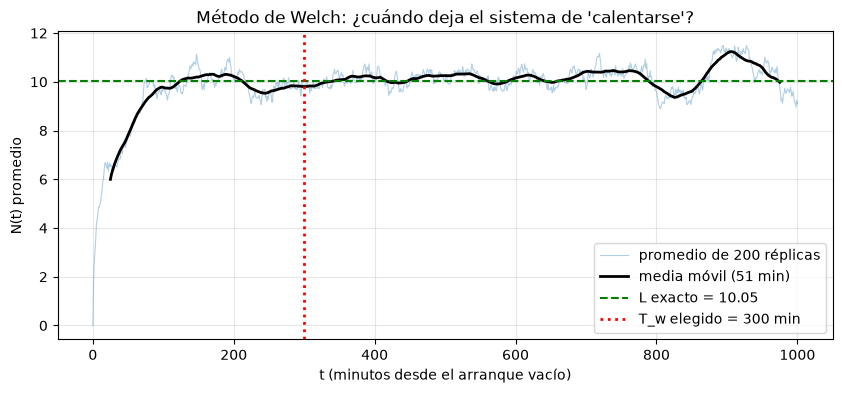

In [4]:
R_welch, T_corta = 200, 1000
grilla = np.arange(0, T_corta + 1, 1.0)                    # un punto por minuto

suma = np.zeros(len(grilla))
for j in range(1, R_welch + 1):
    ts, ns = simular_trayectoria(lam, mu, s, T_corta, semilla=j)
    suma += N_en(ts, ns, grilla)
promedio_replicas = suma / R_welch                          # paso 1: promedio entre réplicas

ventana = 51                                                # paso 2: media móvil de 51 minutos
suavizada = pd.Series(promedio_replicas).rolling(ventana, center=True).mean()

T_w = 300                                                   # elección (ver gráfica)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grilla, promedio_replicas, alpha=0.35, linewidth=0.8, label=f"promedio de {R_welch} réplicas")
ax.plot(grilla, suavizada, color="black", linewidth=2, label=f"media móvil ({ventana} min)")
ax.axhline(L_exacto, color="green", linestyle="--", label=f"L exacto = {L_exacto:.2f}")
ax.axvline(T_w, color="red", linestyle=":", linewidth=2, label=f"T_w elegido = {T_w} min")
ax.set_xlabel("t (minutos desde el arranque vacío)")
ax.set_ylabel("N(t) promedio")
ax.set_title("Método de Welch: ¿cuándo deja el sistema de 'calentarse'?")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

La curva arranca en 0 y sube rápido durante los primeros 100 minutos, aproximadamente. Después deja de tener tendencia y oscila alrededor del valor exacto. Esas oscilaciones son ruido: con $\rho = 0.9$ el sistema es tan variable que incluso el promedio de 200 réplicas se mueve. Elegimos $T_w = 300$ minutos, unas tres veces lo que se ve de transitorio. Es un margen conservador que, en una corrida de decenas de miles de minutos, casi no cuesta nada.

<br>

<div style="background-color: rgba(173, 216, 230, 0.25); padding: 15px; border-left: 5px solid #ADD8E6; border-radius: 5px; margin-bottom: 15px; box-sizing: border-box; overflow-wrap: break-word; width: 100%;">

**Pregunta de control.** ¿Por qué el transitorio de esta central dura unos 100 minutos, mientras que la M/M/2 de la semana 14 ($\rho = 0.8$) se estabiliza en unos 50? *Pista: piensa en cuánto tarda en formarse la fila típica cuando el sistema está muy cargado.*

</div>

## 3. Una corrida larga y *batch means*

Con réplicas independientes, **cada** réplica paga su propio calentamiento. La alternativa es correr **una sola vez**, durante mucho tiempo, y descartar el calentamiento **una sola vez**. El problema es que entonces solo tenemos una corrida, y la semana pasada vimos que no se pueden usar sus clientes como observaciones independientes.

La idea de *batch means* es:

1. Descartar $[0, T_w]$.
2. Dividir el resto, $[T_w, T]$, en $B$ **lotes** de igual duración.
3. Calcular el promedio temporal de $N(t)$ en cada lote: $\bar N_1, \dots, \bar N_B$.
4. Tratar esos $B$ promedios **como si fueran réplicas** y aplicar el intervalo $t$ con $B - 1$ grados de libertad.

¿Por qué funciona? En la semana 14 vimos que la correlación entre clientes **decae** al alejarlos (0.96 entre vecinos, 0.38 a 50 clientes de distancia). Si cada lote es **largo**, lo que pasa al principio de un lote ya casi no depende de lo que pasó al principio del anterior, y los promedios de lote son **aproximadamente independientes**. Hay que comprobarlo: se calcula la autocorrelación $r_1$ entre lotes consecutivos y se busca $|r_1|$ pequeño (regla práctica: menor que 0.2–0.3).

In [5]:
def batch_means(ts, ns, t0, t1, B):
    # Divide [t0, t1] en B lotes de igual duración y devuelve el promedio temporal de N(t) en cada uno
    bordes = np.linspace(t0, t1, B + 1)
    return np.array([promedio_temporal(ts, ns, bordes[b], bordes[b + 1]) for b in range(B)])


def autocorrelacion_lag1(y):
    # Correlación entre cada lote y el siguiente
    return np.corrcoef(y[:-1], y[1:])[0, 1]

In [6]:
T_larga, B = 50_000, 20
ts, ns = simular_trayectoria(lam, mu, s, T_larga, semilla=42)

lotes = batch_means(ts, ns, t0=T_w, t1=T_larga, B=B)
media_bm, hw_bm = ic_t(lotes)
r1 = autocorrelacion_lag1(lotes)

print(f"Corrida de T = {T_larga:,} min, calentamiento T_w = {T_w} min, B = {B} lotes de {(T_larga - T_w) / B:,.0f} min")
print(f"L (batch means) = {media_bm:.3f} ± {hw_bm:.3f}   ->   [{media_bm - hw_bm:.3f}, {media_bm + hw_bm:.3f}]")
print(f"L exacto        = {L_exacto:.3f}")
print(f"r1 entre lotes  = {r1:.3f}")
print(f"Sin descartar el calentamiento, promedio de toda la corrida = {promedio_temporal(ts, ns, 0, T_larga):.3f}")

Corrida de T = 50,000 min, calentamiento T_w = 300 min, B = 20 lotes de 2,485 min
L (batch means) = 9.858 ± 0.771   ->   [9.087, 10.629]
L exacto        = 10.054
r1 entre lotes  = 0.084
Sin descartar el calentamiento, promedio de toda la corrida = 9.832


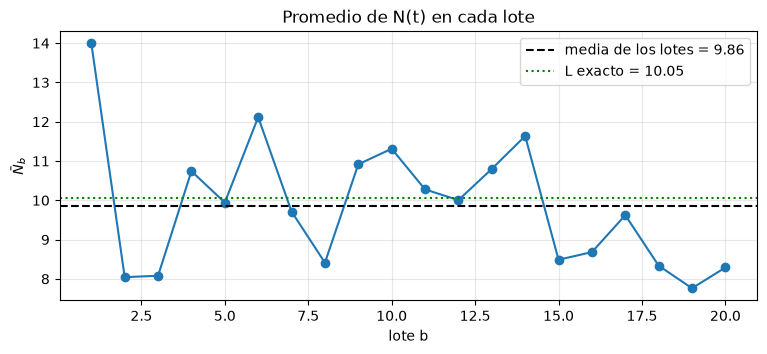

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(np.arange(1, B + 1), lotes, marker="o")
ax.axhline(media_bm, color="black", linestyle="--", label=f"media de los lotes = {media_bm:.2f}")
ax.axhline(L_exacto, color="green", linestyle=":", label=f"L exacto = {L_exacto:.2f}")
ax.set_xlabel("lote b")
ax.set_ylabel(r"$\bar N_b$")
ax.set_title("Promedio de N(t) en cada lote")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Los promedios de lote oscilan alrededor del valor exacto sin tendencia ni rachas largas, $r_1$ es pequeño y el intervalo contiene el valor exacto. Fíjate en la última línea de la salida: en una corrida de 50 000 minutos, incluir o no los primeros 300 casi no cambia el promedio. **El calentamiento importa mucho en réplicas cortas y poco en una corrida muy larga**, pero descartarlo es gratis y elimina la duda.

Para elegir $B$ hay un equilibrio:

- **Pocos lotes** (por ejemplo 5): cada lote es largo e independiente, pero el intervalo tiene pocos grados de libertad y $t_{0.975,\,B-1}$ es grande.
- **Muchos lotes** (por ejemplo 1000): muchos grados de libertad, pero cada lote es corto, los lotes vecinos se correlacionan y el intervalo vuelve a ser optimista, como el "ingenuo" de la semana 14.

Entre **20 y 30 lotes** suele ser un buen punto de partida, siempre comprobando $r_1$. Lo explorarás en el ejercicio aplicado.

## 4. ¿Réplicas o *batch means*?

Comparamos los dos métodos con **el mismo tiempo simulado total** (50 000 minutos):

- **Réplicas:** 10 réplicas de 5 000 minutos; cada una descarta sus propios 300 minutos de calentamiento.
- **Batch means:** la corrida de la sección 3 (descarta 300 minutos una sola vez, 20 lotes).

In [8]:
y_rep = []
for j in range(1, 11):
    ts_j, ns_j = simular_trayectoria(lam, mu, s, 5000, semilla=1000 + j)
    y_rep.append(promedio_temporal(ts_j, ns_j, T_w, 5000))      # descarta el calentamiento de CADA réplica
media_rep, hw_rep = ic_t(y_rep)

pd.DataFrame([
    {"método": "réplicas independientes", "configuración": "R = 10, T = 5 000, T_w = 300 en cada una",
     "tiempo descartado": 10 * T_w, "L estimado": media_rep, "HW": hw_rep},
    {"método": "batch means", "configuración": "1 corrida, T = 50 000, T_w = 300, B = 20",
     "tiempo descartado": T_w, "L estimado": media_bm, "HW": hw_bm},
]).round(3)

,método,configuración,tiempo descartado,L estimado,HW
0,réplicas independientes,"R = 10, T = 5 000, T_w = 300 en cada una",3000,10.212,0.867
1,batch means,"1 corrida, T = 50 000, T_w = 300, B = 20",300,9.858,0.771


Las dos estimaciones son compatibles con el valor exacto ($L = 10.05$). En este experimento *batch means* da un semiancho menor con el mismo presupuesto: descartó 300 minutos en vez de 3 000, así que aprovecha más tiempo simulado, y su intervalo tiene 19 grados de libertad en vez de 9 ($t_{0.975,19} = 2.09$ frente a $t_{0.975,9} = 2.26$). Con un solo experimento no conviene sacar una regla general de cuál HW es menor; la diferencia de fondo está en la tabla siguiente.

| Situación | Conviene |
|---|---|
| El sistema tiene un horizonte natural (abre y cierra: la sucursal, el centro de impresión) | **Réplicas**, una por jornada, sin descartar nada: el arranque vacío es parte del sistema |
| Interesa el largo plazo y el calentamiento es largo o costoso | **Batch means**: el calentamiento se paga una sola vez |
| Interesa el largo plazo y se quiere la independencia "garantizada" | **Réplicas** con calentamiento descartado en cada una |
| Se van a comparar alternativas con números aleatorios comunes (semana 16) | **Réplicas**: se emparejan réplica a réplica |

Con cualquiera de los dos métodos, el reporte incluye $T_w$ además de lo de la semana 14: con *batch means*, "estimación ± HW, 95%, una corrida de $T$, $T_w$, $B$ lotes, semilla y $r_1$".

## Resumen

1. En régimen estacionario, el **arranque vacío sesga** el comienzo de cada corrida. Se descarta un período de calentamiento $T_w$.
2. **Welch:** promediar $N(t)$ entre réplicas, suavizar con media móvil y elegir $T_w$ donde la curva se estabiliza, con margen conservador. Siempre se reporta.
3. **Batch means:** una corrida larga, se descarta $T_w$ una vez, se divide en $B$ lotes y se aplica el intervalo $t$ con $B - 1$ grados de libertad a los promedios de lote.
4. Los lotes deben ser **aproximadamente independientes**: se comprueba con $|r_1|$ pequeño. Muchos lotes cortos vuelven a crear el problema de la semana 14.
5. **Réplicas** para sistemas con jornada y para comparar alternativas; **batch means** cuando el calentamiento es costoso y solo interesa el largo plazo.

---

# Ejercicio aplicado: ¿cuántos lotes?

Usa la corrida larga de la sección 3 (`ts`, `ns`, con $T = 50\,000$ y $T_w = 300$) y aplica *batch means* con $B \in \{5, 10, 20, 50, 200, 1000\}$ lotes. Para cada $B$ reporta en una tabla:

- la duración de cada lote, $(T - T_w)/B$;
- la estimación de $L$ y su HW;
- $r_1$;
- si el intervalo contiene $L$ exacto.

Luego responde:

1. ¿Cómo cambia $r_1$ al aumentar $B$? ¿Por qué?
2. ¿Con qué valores de $B$ confiarías en el intervalo y con cuáles no? Justifica con $r_1$ y con los grados de libertad.
3. **Lo nuevo:** con $B = 1000$, cada lote dura unos 50 minutos. Relaciona eso con la correlación entre clientes de la semana 14. ¿Qué tienen en común un intervalo con lotes muy cortos y el intervalo "ingenuo" construido con todos los clientes de una corrida?

In [9]:
# TODO: para cada B en [5, 10, 20, 50, 200, 1000] calcula lotes = batch_means(ts, ns, T_w, T_larga, B),
#       su IC con ic_t, r1 con autocorrelacion_lag1, y si contiene L_exacto. Organízalo en un DataFrame.

<details>
<summary><b>Pista 1</b></summary>

<br>

Es la celda de la sección 3 dentro de un ciclo `for`. Guarda cada resultado como un diccionario en una lista y al final haz `pd.DataFrame(lista)`.

</details>

<details>
<summary><b>Pista 2</b></summary>

<br>

Compara la duración de los lotes con el transitorio de la sección 2: si un lote dura menos de lo que tarda el sistema en "olvidar" su estado, el lote siguiente empieza donde terminó el anterior.

</details>

<details>
<summary><b>Criterios de revisión</b> (ábrelos solo después de terminar)</summary>

<br>

Tu trabajo está bien encaminado si:

- Con $B$ entre 10 y 50, $|r_1|$ es pequeño y el intervalo contiene el valor exacto.
- Con $B = 5$ el HW es grande por los pocos grados de libertad, y $r_1$, calculado con solo 5 valores, es muy poco confiable.
- Con $B = 1000$ el $r_1$ es claramente positivo y el HW se achica de forma engañosa: los lotes son tan cortos que vuelven a estar correlacionados, igual que los clientes consecutivos de la semana 14. El intervalo "aparenta" precisión que no tiene.

Compara tus números con un compañero y revísalos con tu asistente graduado.

</details>

---

*Universidad de los Andes | Vigilada Mineducación. Reconocimiento como Universidad: Decreto 1297 del 30 de mayo de 1964. Reconocimiento personería jurídica: Resolución 28 del 23 de febrero de 1949 Minjusticia. Departamento de Ingeniería Industrial — Carrera 1 Este No. 19 A 40, Bogotá, Colombia. Tel. (57.1) 3324320 | (57.1) 3394949 Ext. 2880/2881 — http://industrial.uniandes.edu.co*